# Task 2 · Track One Point (30 marks)

Estimate the motion of one point with Lucas-Kanade, and find out when a single
step is enough. Points are `[x, y]`; use the provided `bilinear_sample` for
values at non-integer positions.

**How this notebook works**

* Write your code only in the cells whose first line starts with `# YOUR CODE`.
  Only those cells are graded, and they are read from the **saved** notebook.
  Add your own cells anywhere for experiments or notes: they are never graded.
  A helper function you want graded with your code goes in a `# YOUR CODE` cell
  (a new cell whose first line is `# YOUR CODE` works too).
* Run the `check(...)` cell after your code: it tests your functions and prints
  PASS or FAIL for each test.
* Answer each question in the cell right below it, in one or two sentences,
  replacing *TODO*.
* Save often (Ctrl+S). Before you submit, run everything from a clean start:
  restart the kernel and run all cells, or run `python run_notebooks.py`.

In [3]:
# PROVIDED: run this cell first (save task1.ipynb before)
%matplotlib inline
import numpy as np
from provided.notebook import check, use_my_functions
from provided.sampling import bilinear_sample
from provided.task2.steps import error_sweep, real_pair

use_my_functions(1)               # your Task 1 functions, from the saved task1.ipynb

your functions from task1.ipynb (the saved files): spatial_gradients, temporal_difference, structure_tensor, feature_score, select_features


## 2.1 Lucas-Kanade as least squares (12 marks)

Assume constant motion in a local window and solve, with NumPy linear algebra,

$$
A\begin{bmatrix}u\\ v\end{bmatrix}\approx b,\qquad b=-\begin{bmatrix}I_{t1}\\ \vdots\\ I_{tN}\end{bmatrix}.
$$

In [4]:
# YOUR CODE: Task 2.1

def lucas_kanade_update(ix_window, iy_window, it_window):
    """One least-squares Lucas-Kanade step, equation (2.1).

    ix_window, iy_window, it_window : same-shaped arrays of Ix, Iy and It over
    one window. Returns (u, v) as two floats, or None if it cannot be solved.

    How to write it:
      1. A has one row [Ix, Iy] per pixel, shape (N, 2):
         A = np.stack([ix_window.ravel(), iy_window.ravel()], axis=1); b = -It, flattened.
      2. G = A.T @ A (the matrix of Task 1.3). If its smaller eigenvalue,
         np.linalg.eigvalsh(G)[0], is below about 1e-8, return None.
      3. Solve G [u, v] = A.T @ b with np.linalg.solve.
    """

    A = np.stack([ix_window.ravel(), iy_window.ravel()], axis=1)
    b = -it_window.ravel()
    G = A.T @ A

    if np.linalg.eigvalsh(G)[0] < 1e-8:
        return None

    return np.linalg.solve(G, A.T @ b)
   

In [5]:
check("2.1")

Task 2.1 checks
  PASS  lucas kanade update solves exact motion
  PASS  lucas kanade update rejects a flat window
2 of 2 passed


True

**(a)** Write the least-squares solution for $(u, v)$ using $G = A^TA$.

Given $A\begin{bmatrix}u\\v\end{bmatrix}\approx b$, minimize the squared error. The normal equations are
$$
A^TA\begin{bmatrix}u\\v\end{bmatrix}=A^Tb.
$$

Since $G=A^TA$, the solution is
$$

\begin{bmatrix}u\\v\end{bmatrix}
=G^{-1}A^Tb

$$

**(b)** When can it not be solved? Relate this to $q$ from Task 1.3.

The solution cannot be uniquely determined when \(G\) is singular, meaning at least one eigenvalue is zero. This occurs when the image gradients do not provide independent constraints on both motion components, such as on a flat patch or an ideal edge

## 2.2 Estimate one-step motion (9 marks)

Sample the gradient and temporal-difference windows at a point (with the
provided bilinear sampling) and solve once. The tests below and the Task 2.3
sweep check it on synthetic sub-pixel shifts.

In [7]:
# YOUR CODE: Task 2.2

def one_step_flow(image0, image1, point, window_radius=7, grad0=None):
      """A single Lucas-Kanade update at one point (Task 2.2), without iterating.

      grad0 : optional (ix, iy) of image0, so many calls can share one gradient
               computation.
      Returns (u, v), or None if the window leaves the image or the update fails.

      How to write it:
         1. ix, iy = grad0, or spatial_gradients(image0) when grad0 is None.
         2. The window around point = (x, y), with window_radius = window_radius:
            dy, dx = np.mgrid[-window_radius:window_radius + 1, -window_radius:window_radius + 1]; xs, ys = x + dx, y + dy.
         3. Return None unless the window stays at least 1 pixel inside the image
            (Ix and Iy are 0 on the border).
         4. bilinear_sample(img, xs, ys) returns (values, inside). Sample Ix, Iy,
            image0 and image1 on the window; It = image1 values - image0 values.
         5. Return lucas_kanade_update(Ix values, Iy values, It).
      """
      # 1. Compute or reuse spatial gradients for image0
      if grad0 is None:
         ix, iy = spatial_gradients(image0)
      else:
         ix, iy = grad0

      # Extract coordinates and image dimensions
      x, y = point
      H, W = image0.shape

      # 2. Construct window coordinates centered at (x, y)
      dy, dx = np.mgrid[-window_radius:window_radius + 1, -window_radius:window_radius + 1]
      xs = x + dx
      ys = y + dy

      # 3. Check that the entire window stays at least 1 pixel inside the border
      # (Border row 0, row H-1, col 0, col W-1 have 0 gradients)
      if np.any(xs < 1) or np.any(xs >= W - 1) or np.any(ys < 1) or np.any(ys >= H - 1):
         return None

      # 4. Sample Ix, Iy, image0, and image1 values using bilinear sampling
      ix_vals, _ = bilinear_sample(ix, xs, ys)
      iy_vals, _ = bilinear_sample(iy, xs, ys)
      i0_vals, _ = bilinear_sample(image0, xs, ys)
      i1_vals, _ = bilinear_sample(image1, xs, ys)

      # Compute temporal gradient It = image1 - image0
      it_vals = i1_vals - i0_vals

      # 5. Compute and return Lucas-Kanade update (u, v)
      return lucas_kanade_update(ix_vals, iy_vals, it_vals)
      

In [8]:
check("2.2")

Task 2.2 checks
  PASS  one step flow recovers a small shift
  PASS  one step flow fails when the window leaves the image
  PASS  one step flow can reuse precomputed gradients
3 of 3 passed


True

**(a)** How large is the error of `one_step_flow` on sub-pixel shifts? See the smallest shifts of the Task 2.3 sweep (`error_sweep.json`).

For sub-pixel shifts, the one-step flow error is very small, approximately 0.002–0.015 pixels for the smallest tested shifts.

## 2.3 When one step is not enough (9 marks)

The provided cells run a sweep of synthetic shifts from 0.1 to 8 px, and
one-step flow on two real pairs: pair A, 375 to 376, where the motion is small
(the hover), and pair B, 300 to 301, where it is much larger (mid-descent).

In [9]:
check("2.3")

Task 2.3 checks
  PASS  one step flow gets worse as the shift grows
1 of 1 passed


True

  saved outputs/task2/error_sweep.json
  saved outputs/task2/error_sweep.png


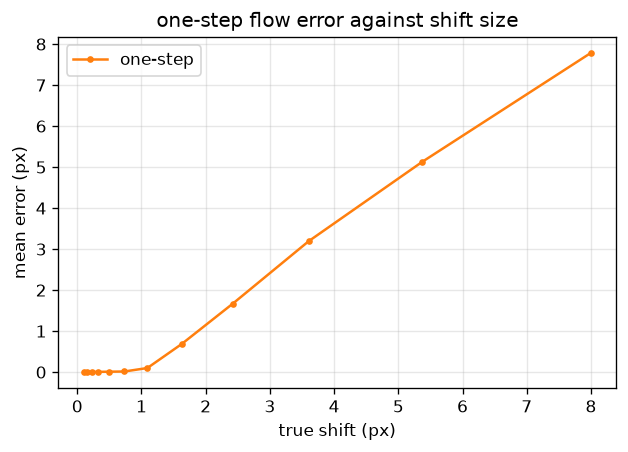

    shift  0.10 px: mean error 0.002 px
    shift  0.15 px: mean error 0.003 px
    shift  0.22 px: mean error 0.005 px
    shift  0.33 px: mean error 0.007 px
    shift  0.49 px: mean error 0.010 px
    shift  0.73 px: mean error 0.015 px
    shift  1.09 px: mean error 0.100 px
    shift  1.63 px: mean error 0.685 px
    shift  2.42 px: mean error 1.670 px
    shift  3.61 px: mean error 3.197 px
    shift  5.37 px: mean error 5.128 px
    shift  8.00 px: mean error 7.788 px


In [10]:
curves = error_sweep(select_features, spatial_gradients, one_step_flow)

  small_motion (375 to 376): 59 of 60 windows solved, mean step 1.07 px
  saved outputs/task2/one_step_small_motion.png


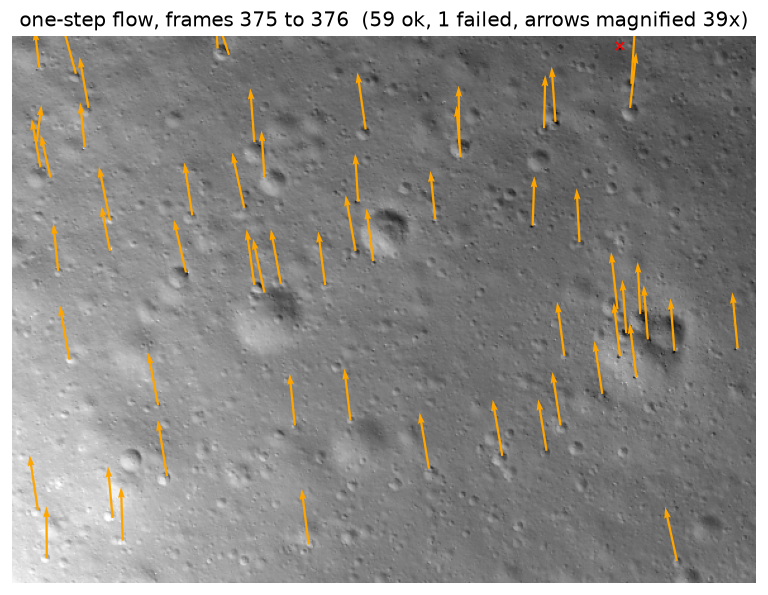

  large_motion (300 to 301): 55 of 60 windows solved, mean step 0.30 px
  saved outputs/task2/one_step_large_motion.png


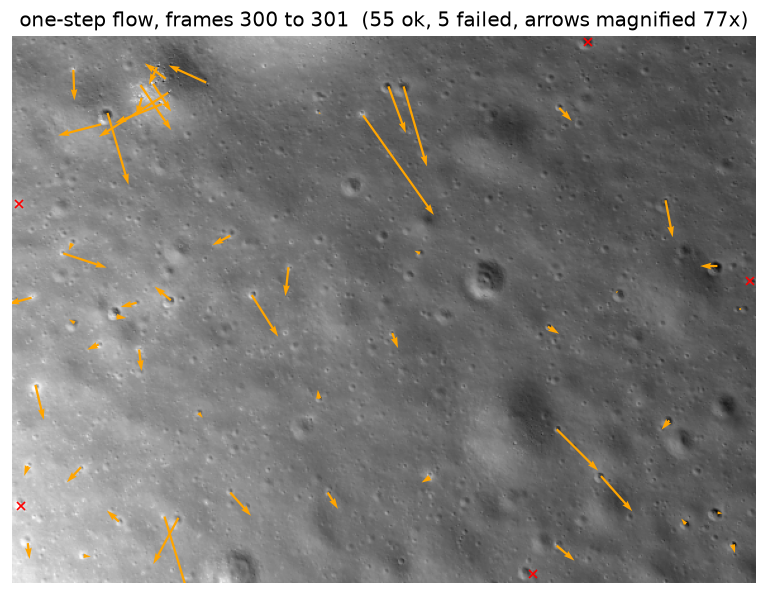

In [11]:
step_a = real_pair("small_motion", 375, 376, select_features, spatial_gradients, one_step_flow)
step_b = real_pair("large_motion", 300, 301, select_features, spatial_gradients, one_step_flow)

**(a)** Above what shift does the one-step error grow quickly?

The one-step error grows quickly for shifts above approximately 1 pixel, as the first-order linearization becomes less accurate for larger displacements.

**(b)** Why does one step come close on pair A (375 to 376) but badly undershoot pair B (300 to 301)?

Pair A (375 to 376) has smaller motion, so the linear approximation works well and estimates the displacement accurately. Pair B (300 to 301) has larger motion, violating the small-displacement assumption; consequently, one-step Lucas–Kanade underestimates the true displacement.